# Stream A — 04 Results

This notebook evaluates Stream A features.

Because NewsCLIPpings currently has no local images, the main local-image classifier is trained on `mmfakebench_val` and evaluated on:
- `mmfakebench_test`
- `verite_test`

NewsCLIPpings is still summarized, but image-grounding features are unavailable for it unless pre-extracted image embeddings are integrated later.


In [1]:
from pathlib import Path
import sys, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer

def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "data").exists() and (q / "src").exists():
            return q
    raise RuntimeError("Could not find repo root.")

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from src.utils.paths import STREAM_A_CACHE, FIGURES, TABLES

FEAT_CACHE = STREAM_A_CACHE / "entity_scorer"
RESULT_CACHE = STREAM_A_CACHE / "results"
RESULT_CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("FEAT_CACHE:", FEAT_CACHE)


ROOT: E:\eve-rag
FEAT_CACHE: E:\eve-rag\cache\stream_a\entity_scorer


In [2]:
features_path = FEAT_CACHE / "features_all.csv"
if not features_path.exists():
    raise FileNotFoundError(f"Missing {features_path}. Run entity_scorer_v2_updated.ipynb first.")

features = pd.read_csv(features_path, low_memory=False)
print(features.shape)
features.head()


(97361, 17)


,pair_id,dataset,split,label,has_image,n_entities,n_person,n_gpe,n_org,max_grounding,min_grounding,mean_grounding,person_max,gpe_max,org_max,caption_clip_sim,n_grounded_entities
0,nc_620701_0,newsclippings,train,0,0,3,0,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,nc_620701_1,newsclippings,train,1,0,3,0,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,nc_1569820_0,newsclippings,train,0,0,2,0,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,nc_1569820_1,newsclippings,train,1,0,3,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,nc_1490080_0,newsclippings,train,0,0,1,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [3]:
FEATURE_COLS = [
    "n_entities", "n_person", "n_gpe", "n_org",
    "max_grounding", "min_grounding", "mean_grounding",
    "person_max", "gpe_max", "org_max",
    "caption_clip_sim", "n_grounded_entities",
]

def eval_binary(y_true, y_pred, y_score=None):
    out = {
        "acc": accuracy_score(y_true, y_pred) * 100,
        "precision": precision_score(y_true, y_pred, zero_division=0) * 100,
        "recall": recall_score(y_true, y_pred, zero_division=0) * 100,
        "f1": f1_score(y_true, y_pred, zero_division=0) * 100,
    }
    if y_score is not None and len(np.unique(y_true)) > 1:
        try:
            out["auroc"] = roc_auc_score(y_true, y_score) * 100
        except Exception:
            out["auroc"] = np.nan
    else:
        out["auroc"] = np.nan
    return out

def fmt_metrics(d):
    return {k: (round(v, 2) if isinstance(v, (float, int)) and not pd.isna(v) else v) for k, v in d.items()}


In [4]:
# Train on MMFakeBench validation because it has local images and labels.
train_df = features[(features["dataset"] == "mmfakebench") & (features["split"] == "val")].copy()
test_mmfake = features[(features["dataset"] == "mmfakebench") & (features["split"] == "test")].copy()
test_verite = features[(features["dataset"] == "verite") & (features["split"] == "test") & (features["has_image"] == 1)].copy()

print("Train MMFake val:", train_df.shape)
print("Test MMFake:", test_mmfake.shape)
print("Test VERITE local-image rows:", test_verite.shape)

X_train = train_df[FEATURE_COLS]
y_train = train_df["label"].astype(int)

clf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

clf.fit(X_train, y_train)
print("Trained Stream A LR.")


Train MMFake val: (1000, 17)
Test MMFake: (10000, 17)
Test VERITE local-image rows: (621, 17)
Trained Stream A LR.


In [5]:
results = []
pred_frames = []

for name, sub in [
    ("mmfakebench_test", test_mmfake),
    ("verite_test_local", test_verite),
]:
    if len(sub) == 0:
        continue

    X = sub[FEATURE_COLS]
    y = sub["label"].astype(int).values
    prob = clf.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)

    metrics = fmt_metrics(eval_binary(y, pred, prob))
    results.append({"method": "stream_a_lr", "dataset": name, **metrics})

    # Majority baseline
    majority = int(y_train.mean() >= 0.5)
    maj_pred = np.full_like(y, majority)
    results.append({"method": "majority_train", "dataset": name, **fmt_metrics(eval_binary(y, maj_pred))})

    # caption_clip_sim threshold baseline when available
    if sub["caption_clip_sim"].notna().sum() > 0:
        score = -sub["caption_clip_sim"].fillna(sub["caption_clip_sim"].median()).values
        pred_thr = (score >= np.nanmedian(score)).astype(int)
        results.append({"method": "caption_clip_sim_median", "dataset": name, **fmt_metrics(eval_binary(y, pred_thr, score))})

    pf = sub[["pair_id", "dataset", "split", "label"]].copy()
    pf["stream_a_score"] = prob
    pf["stream_a_pred"] = pred
    pf["eval_dataset"] = name
    pred_frames.append(pf)

results_df = pd.DataFrame(results)
pred_df = pd.concat(pred_frames, ignore_index=True) if pred_frames else pd.DataFrame()

results_df.to_csv(TABLES / "stream_a_results.csv", index=False)
pred_df.to_csv(RESULT_CACHE / "stream_a_predictions.csv", index=False)

results_df


,method,dataset,acc,precision,recall,f1,auroc
0,stream_a_lr,mmfakebench_test,62.56,78.19,64.51,70.70,65.41
1,majority_train,mmfakebench_test,70.00,70.00,100.00,82.35,NaN
2,caption_clip_sim_median,mmfakebench_test,58.10,78.10,55.79,65.08,64.14
3,stream_a_lr,verite_test_local,53.30,69.04,54.00,60.60,53.83
4,majority_train,verite_test_local,66.51,66.51,100.00,79.88,NaN
5,caption_clip_sim_median,verite_test_local,48.47,64.95,48.91,55.80,47.82


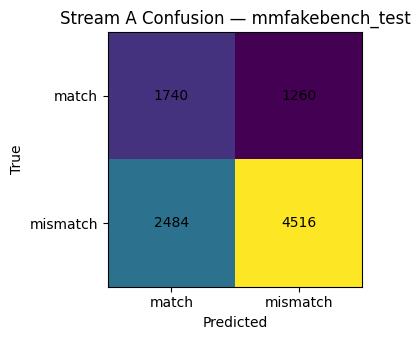

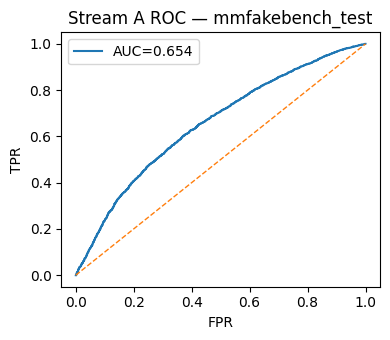

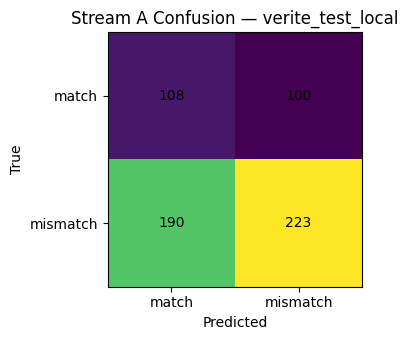

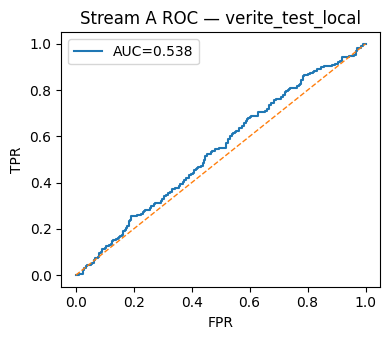

In [6]:
# Save confusion matrices and ROC curves.
for eval_name, sub_pred in pred_df.groupby("eval_dataset"):
    y = sub_pred["label"].astype(int).values
    pred = sub_pred["stream_a_pred"].astype(int).values
    score = sub_pred["stream_a_score"].values

    cm = confusion_matrix(y, pred)
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ax.imshow(cm)
    ax.set_title(f"Stream A Confusion — {eval_name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["match", "mismatch"])
    ax.set_yticklabels(["match", "mismatch"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(FIGURES / f"stream_a_confusion_{eval_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

    if len(np.unique(y)) > 1:
        fpr, tpr, _ = roc_curve(y, score)
        auc = roc_auc_score(y, score)
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ax.plot(fpr, tpr, label=f"AUC={auc:.3f}")
        ax.plot([0, 1], [0, 1], "--", linewidth=1)
        ax.set_title(f"Stream A ROC — {eval_name}")
        ax.set_xlabel("FPR")
        ax.set_ylabel("TPR")
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIGURES / f"stream_a_roc_{eval_name}.png", dpi=200, bbox_inches="tight")
        plt.show()


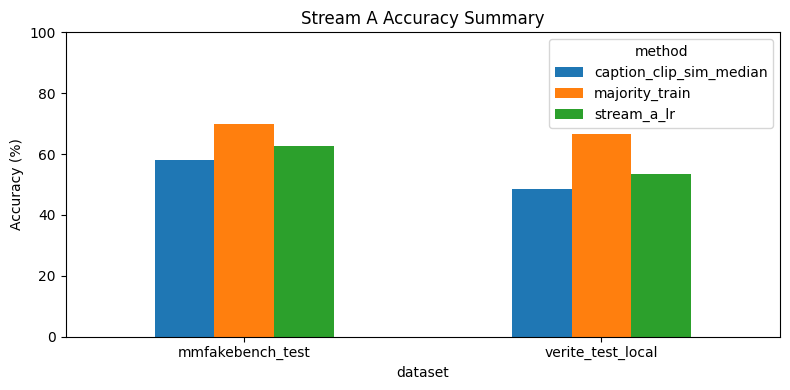

method,caption_clip_sim_median,majority_train,stream_a_lr
dataset,,,
mmfakebench_test,58.10,70.00,62.56
verite_test_local,48.47,66.51,53.30


In [7]:
# Summary bar.
if not results_df.empty:
    pivot = results_df.pivot_table(index="dataset", columns="method", values="acc", aggfunc="first")
    ax = pivot.plot(kind="bar", figsize=(8, 4))
    ax.set_title("Stream A Accuracy Summary")
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 100)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(FIGURES / "stream_a_summary_bar.png", dpi=200, bbox_inches="tight")
    plt.show()

pivot if not results_df.empty else results_df


In [8]:
print("=" * 60)
print("Stream A results complete.")
print("Saved:")
print(" ", TABLES / "stream_a_results.csv")
print(" ", RESULT_CACHE / "stream_a_predictions.csv")
print("=" * 60)


Stream A results complete.
Saved:
  E:\eve-rag\paper\tables\stream_a_results.csv
  E:\eve-rag\cache\stream_a\results\stream_a_predictions.csv
